In [1]:

# 1. Install gdown
!pip -q install gdown

# 2. Download your Google Drive ZIP file
import gdown
import os

file_id = "1njl-hWUG7OEQVilJ4f8w77YuZe7EXrtM"
zip_path = "/kaggle/working/dataset.zip"

url = f"https://drive.google.com/uc?id={file_id}"

gdown.download(url, zip_path, quiet=False)

# 3. Verify the download
if os.path.exists(zip_path):
    print(f"Download complete: {zip_path}")
    print(f"File size: {os.path.getsize(zip_path) / (1024**3):.2f} GB")
else:
    print("Download failed. Check the Drive sharing permissions.")


Downloading...
From (original): https://drive.google.com/uc?id=1njl-hWUG7OEQVilJ4f8w77YuZe7EXrtM
From (redirected): https://drive.google.com/uc?id=1njl-hWUG7OEQVilJ4f8w77YuZe7EXrtM&confirm=t&uuid=e68b4cae-9ebf-4e94-8b68-0215e2fa4280
To: /kaggle/working/dataset.zip
100%|██████████| 804M/804M [00:05<00:00, 148MB/s]

Download complete: /kaggle/working/dataset.zip
File size: 0.75 GB


In [2]:

import zipfile
import os

zip_path = "/kaggle/working/dataset.zip"
extract_path = "/kaggle/working/dataset"

if os.path.isfile(zip_path) and zipfile.is_zipfile(zip_path):
    with zipfile.ZipFile(zip_path, "r") as z:
        z.extractall(extract_path)
    print("Extracted to:", extract_path)
    print("Files:", os.listdir(extract_path)[:20])
else:
    print("ZIP file is missing, incomplete, or invalid.")


Extracted to: /kaggle/working/dataset
Files: ['noise_project_v2']


In [3]:

import os

folder = "/kaggle/working/dataset/noise_project_v2"

for root, dirs, files in os.walk(folder):
    level = root.replace(folder, "").count(os.sep)
    indent = "    " * level
    print(f"{indent}{os.path.basename(root)}/")

    subindent = "    " * (level + 1)
    for file in files[:20]:
        print(f"{subindent}{file}")

    if level >= 3:
        dirs.clear()


noise_project_v2/
    noise_manifest_v2.json
    clean_list.csv
    noisy_metadata_v2.csv
    b6000_split.csv
    clean_500/
        S/
            00002604_S_500_slap_08.png
            00002466_S_500_slap_04.png
            00002568_S_500_slap_02.png
            00002604_S_500_slap_06.png
            00002633_S_500_slap_06.png
            00002591_S_500_slap_02.png
            00002581_S_500_slap_02.png
            00002636_S_500_slap_06.png
            00002542_S_500_slap_09.png
            00002591_S_500_slap_06.png
            00002496_S_500_slap_01.png
            00002641_S_500_slap_08.png
            00002508_S_500_slap_09.png
            00002636_S_500_slap_01.png
            00002488_S_500_slap_01.png
            00002630_S_500_slap_06.png
            00002556_S_500_slap_06.png
            00002483_S_500_slap_09.png
            00002495_S_500_slap_05.png
            00002649_S_500_slap_03.png
        V/
            00002550_V_500_roll_01.png
            00002523_V_500_roll_08

In [4]:

from pathlib import Path
from collections import Counter

folder = Path("/kaggle/working/dataset/noise_project_v2")

files = [p for p in folder.rglob("*") if p.is_file()]

print("Total files:", len(files))
print("\nFile types:")
print(Counter(p.suffix.lower() or "[no extension]" for p in files))

print("\nFirst 30 file paths:")
for p in files[:30]:
    print(p.relative_to(folder))


Total files: 4984

File types:
Counter({'.png': 4980, '.csv': 3, '.json': 1})

First 30 file paths:
noise_manifest_v2.json
clean_list.csv
noisy_metadata_v2.csv
b6000_split.csv
noisy_500_v2/S/00002604_S_500_slap_08.png
noisy_500_v2/S/00002466_S_500_slap_04.png
noisy_500_v2/S/00002568_S_500_slap_02.png
noisy_500_v2/S/00002604_S_500_slap_06.png
noisy_500_v2/S/00002633_S_500_slap_06.png
noisy_500_v2/S/00002591_S_500_slap_02.png
noisy_500_v2/S/00002581_S_500_slap_02.png
noisy_500_v2/S/00002636_S_500_slap_06.png
noisy_500_v2/S/00002542_S_500_slap_09.png
noisy_500_v2/S/00002591_S_500_slap_06.png
noisy_500_v2/S/00002496_S_500_slap_01.png
noisy_500_v2/S/00002641_S_500_slap_08.png
noisy_500_v2/S/00002508_S_500_slap_09.png
noisy_500_v2/S/00002636_S_500_slap_01.png
noisy_500_v2/S/00002488_S_500_slap_01.png
noisy_500_v2/S/00002630_S_500_slap_06.png
noisy_500_v2/S/00002556_S_500_slap_06.png
noisy_500_v2/S/00002483_S_500_slap_09.png
noisy_500_v2/S/00002495_S_500_slap_05.png
noisy_500_v2/S/00002649_S_

In [5]:
!pip install -q "nbis-python>=0.1.17" scikit-image

import os, time, random
from pathlib import Path
import numpy as np, pandas as pd, cv2, torch
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader
from skimage.metrics import structural_similarity as ssim_fn
from PIL import Image
import matplotlib.pyplot as plt
from tqdm.auto import tqdm

ROOT = Path("/kaggle/working/dataset/noise_project_v2")
CLEAN_DIR, NOISY_DIR = ROOT/"clean_500", ROOT/"noisy_500_v2"
OUT = Path("/kaggle/working/finger_unet")
for d in ["ckpt", "enhanced_test", "visuals"]:
    (OUT/d).mkdir(parents=True, exist_ok=True)

SEED = 42
random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED); torch.cuda.manual_seed_all(SEED)
device = torch.device("cuda")
print(torch.__version__, torch.cuda.get_device_name(0))

2.11.0+cu128 Tesla T4


In [6]:
split_df = pd.read_csv(ROOT/"b6000_split.csv")
print(split_df.shape); print(split_df.head())
for c in split_df.columns:
    if split_df[c].nunique() <= 10:
        print(c, split_df[c].value_counts().to_dict())
for f in sorted(CLEAN_DIR.rglob("*.png"))[:5]:
    im = cv2.imread(str(f), 0); print(f.name, im.shape, im.dtype)

(6000, 30)
  source                     key  participant device  ppi         capture  \
0      b  00002302_R_500_slap_01         2302      R  500  slap-segmented   
1      b  00002302_R_500_slap_02         2302      R  500  slap-segmented   
2      b  00002302_R_500_slap_03         2302      R  500  slap-segmented   
3      b  00002302_R_500_slap_04         2302      R  500  slap-segmented   
4      b  00002302_R_500_slap_05         2302      R  500  slap-segmented   

   frgp finger_name                                         zip_member  \
0     1     R thumb  sd302b/images/baseline/R/500/slap-segmented/pn...   
1     2     R index  sd302b/images/baseline/R/500/slap-segmented/pn...   
2     3    R middle  sd302b/images/baseline/R/500/slap-segmented/pn...   
3     4      R ring  sd302b/images/baseline/R/500/slap-segmented/pn...   
4     5    R little  sd302b/images/baseline/R/500/slap-segmented/pn...   

                                              sha256  ...  items_9_325  \
0  c5ee

In [7]:
clean_idx = {p.name: p for p in CLEAN_DIR.rglob("*.png")}
noisy_idx = {p.name: p for p in NOISY_DIR.rglob("*.png")}
print("clean:", len(clean_idx), "noisy:", len(noisy_idx))

def find_split_col(d):
    names = {"train", "val", "valid", "validation", "test"}
    for c in d.columns:
        v = set(str(x).strip().lower() for x in d[c].dropna().unique())
        if v and v <= names: return c
def find_name_col(d):
    for c in d.columns:
        s = d[c].dropna().astype(str)
        if len(s) and s.str.lower().str.endswith(".png").mean() > 0.9: return c

split_col, name_col = find_split_col(split_df), find_name_col(split_df)
print("split col:", split_col, "| name col:", name_col)
assert split_col and name_col, "Columns detect nahi hue -> Cell 2 ka output mujhe bhej do"

df = split_df.copy()
df["fname"] = df[name_col].astype(str).map(lambda s: os.path.basename(s.replace("\\", "/")))
df["split"] = (df[split_col].astype(str).str.strip().str.lower()
               .replace({"valid": "val", "validation": "val"}))
df = df.drop_duplicates("fname")
df = df[df.fname.isin(clean_idx) & df.fname.isin(noisy_idx)].reset_index(drop=True)
df["noisy"] = df.fname.map(noisy_idx).astype(str)
df["clean"] = df.fname.map(clean_idx).astype(str)
df["device"] = df.fname.str.split("_").str[1]

print(df.split.value_counts())
print(pd.crosstab(df.device, df.split))
train_df = df[df.split == "train"].reset_index(drop=True)
val_df   = df[df.split == "val"].reset_index(drop=True)
test_df  = df[df.split == "test"].reset_index(drop=True)

clean: 2490 noisy: 2490
split col: split | name col: zip_member
split
train    1764
val       388
test      338
Name: count, dtype: int64
split   test  train  val
device                  
R         60    314   85
S         93    502   83
U        104    477  123
V         81    471   97


In [8]:
CROP = 256
def _pad_to(img, s):
    h, w = img.shape
    ph, pw = max(0, s-h), max(0, s-w)
    return cv2.copyMakeBorder(img, 0, ph, 0, pw, cv2.BORDER_REFLECT) if (ph or pw) else img

class PairDS(Dataset):
    def __init__(self, d, train, repeat=1):
        self.d, self.train, self.repeat = d.reset_index(drop=True), train, repeat
    def __len__(self): return len(self.d) * self.repeat
    def __getitem__(self, i):
        r = self.d.iloc[i % len(self.d)]
        n = cv2.imread(r.noisy, 0); c = cv2.imread(r.clean, 0)
        n, c = _pad_to(n, CROP), _pad_to(c, CROP)
        h, w = n.shape
        if self.train:
            y, x = random.randint(0, h-CROP), random.randint(0, w-CROP)
            n, c = n[y:y+CROP, x:x+CROP], c[y:y+CROP, x:x+CROP]
            if random.random() < .5: n, c = n[:, ::-1], c[:, ::-1]
            if random.random() < .5: n, c = n[::-1], c[::-1]
            k = random.randint(0, 3); n, c = np.rot90(n, k), np.rot90(c, k)
        else:
            y, x = (h-CROP)//2, (w-CROP)//2
            n, c = n[y:y+CROP, x:x+CROP], c[y:y+CROP, x:x+CROP]
        f = lambda a: torch.from_numpy(np.ascontiguousarray(a)).float().div(255).unsqueeze(0)
        return f(n), f(c)

BS = 16
tr_dl = DataLoader(PairDS(train_df, True, repeat=2), batch_size=BS, shuffle=True,
                   num_workers=4, pin_memory=True, drop_last=True, persistent_workers=True)
va_dl = DataLoader(PairDS(val_df, False), batch_size=32, num_workers=2)
x, y = next(iter(tr_dl)); print(x.shape, y.shape, x.min().item(), x.max().item())

torch.Size([16, 1, 256, 256]) torch.Size([16, 1, 256, 256]) 0.0 1.0


In [9]:
class Block(nn.Module):
    def __init__(s, cin, cout, ds=True):
        super().__init__()
        def conv(i, o):
            if ds:  # depthwise separable
                return nn.Sequential(nn.Conv2d(i, i, 3, padding=1, groups=i, bias=False),
                                     nn.Conv2d(i, o, 1, bias=False), nn.BatchNorm2d(o), nn.ReLU(True))
            return nn.Sequential(nn.Conv2d(i, o, 3, padding=1, bias=False), nn.BatchNorm2d(o), nn.ReLU(True))
        s.net = nn.Sequential(conv(cin, cout), conv(cout, cout))
    def forward(s, x): return s.net(x)

class WA(nn.Module):
    """Haar DWT + wavelet attention (Zhao et al. 2022), replaces max-pool. HH not used."""
    def forward(s, x):
        a, b = x[:, :, 0::2, 0::2], x[:, :, 0::2, 1::2]
        c, d = x[:, :, 1::2, 0::2], x[:, :, 1::2, 1::2]
        ll = (a + b + c + d) / 2
        lh = (a + b - c - d) / 2
        hl = (a - b + c - d) / 2
        g = torch.softmax((lh + hl).float(), dim=1).to(ll.dtype)  # xg = softmax(f(LH, HL))
        return ll + ll * g                                         # Z = LL + LL*xg

class FingerUNet(nn.Module):
    def __init__(s, ch=(32, 64, 128, 256, 512)):
        super().__init__()
        c1, c2, c3, c4, c5 = ch
        s.e1 = Block(1, c1, ds=False)
        s.e2, s.e3, s.e4, s.b = Block(c1, c2), Block(c2, c3), Block(c3, c4), Block(c4, c5)
        s.wa = WA()
        s.u4, s.d4 = nn.ConvTranspose2d(c5, c4, 2, 2), Block(c4*2, c4)
        s.u3, s.d3 = nn.ConvTranspose2d(c4, c3, 2, 2), Block(c3*2, c3)
        s.u2, s.d2 = nn.ConvTranspose2d(c3, c2, 2, 2), Block(c2*2, c2)
        s.u1, s.d1 = nn.ConvTranspose2d(c2, c1, 2, 2), Block(c1*2, c1)
        s.out = nn.Conv2d(c1, 1, 1)
    def forward(s, x):
        e1 = s.e1(x)
        e2 = s.e2(s.wa(e1))
        e3 = s.e3(s.wa(e2))
        e4 = s.e4(s.wa(e3))
        b  = s.b(s.wa(e4))
        d4 = s.d4(torch.cat([s.u4(b),  e4], 1))
        d3 = s.d3(torch.cat([s.u3(d4), e3], 1))
        d2 = s.d2(torch.cat([s.u2(d3), e2], 1))
        d1 = s.d1(torch.cat([s.u1(d2), e1], 1))
        return torch.sigmoid(s.out(d1))

model = FingerUNet().to(device)
print("params (M):", sum(p.numel() for p in model.parameters()) / 1e6)
with torch.no_grad(): print(model(torch.zeros(1, 1, 256, 256, device=device)).shape)

params (M): 1.521505
torch.Size([1, 1, 256, 256])


ep   1/100 | train L1 0.1412 | val L1 0.1311 | val PSNR 13.48 | 65s
ep   2/100 | train L1 0.1058 | val L1 0.1375 | val PSNR 12.95 | 34s
ep   3/100 | train L1 0.0971 | val L1 0.1073 | val PSNR 15.07 | 35s
ep   4/100 | train L1 0.0912 | val L1 0.1065 | val PSNR 15.17 | 34s
ep   5/100 | train L1 0.0859 | val L1 0.1358 | val PSNR 13.84 | 35s
ep   6/100 | train L1 0.0828 | val L1 0.0966 | val PSNR 15.61 | 34s
ep   7/100 | train L1 0.0797 | val L1 0.0931 | val PSNR 15.85 | 34s
ep   8/100 | train L1 0.0789 | val L1 0.1017 | val PSNR 15.67 | 34s
ep   9/100 | train L1 0.0775 | val L1 0.1036 | val PSNR 15.62 | 35s
ep  10/100 | train L1 0.0751 | val L1 0.0891 | val PSNR 16.22 | 34s
ep  11/100 | train L1 0.0744 | val L1 0.1368 | val PSNR 13.83 | 34s
ep  12/100 | train L1 0.0725 | val L1 0.0837 | val PSNR 16.80 | 34s
ep  13/100 | train L1 0.0722 | val L1 0.0859 | val PSNR 16.52 | 34s
ep  14/100 | train L1 0.0723 | val L1 0.0866 | val PSNR 16.39 | 35s
ep  15/100 | train L1 0.0710 | val L1 0.0821 | v

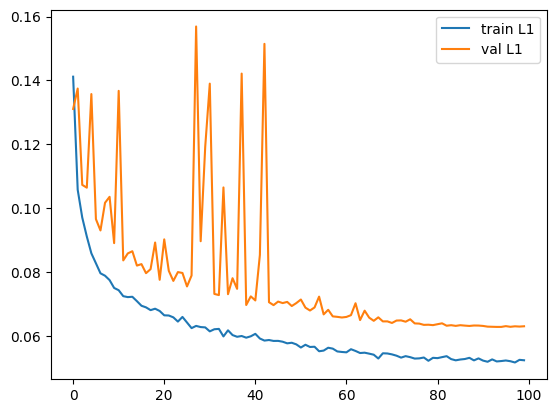

In [10]:
EPOCHS, LR, RESUME = 100, 1e-3, True
opt = torch.optim.Adam(model.parameters(), lr=LR)
sched = torch.optim.lr_scheduler.CosineAnnealingLR(opt, T_max=EPOCHS, eta_min=1e-5)
scaler = torch.amp.GradScaler("cuda")
crit = nn.L1Loss()
start, best, hist = 0, 1e9, []
last = OUT/"ckpt/last.pt"
if RESUME and last.exists():
    ck = torch.load(last, map_location=device)
    model.load_state_dict(ck["model"]); opt.load_state_dict(ck["opt"])
    sched.load_state_dict(ck["sched"]); scaler.load_state_dict(ck["scaler"])
    start, best, hist = ck["epoch"] + 1, ck["best"], ck["hist"]
    print("Resumed from epoch", start)

for ep in range(start, EPOCHS):
    model.train(); t0 = time.time(); tl = n = 0
    for x, y in tr_dl:
        x, y = x.to(device, non_blocking=True), y.to(device, non_blocking=True)
        opt.zero_grad(set_to_none=True)
        with torch.autocast("cuda", dtype=torch.float16):
            p = model(x)
        loss = crit(p.float(), y)
        scaler.scale(loss).backward(); scaler.step(opt); scaler.update()
        tl += loss.item() * len(x); n += len(x)
    sched.step()

    model.eval(); vl = vm = m = 0
    with torch.no_grad(), torch.autocast("cuda", dtype=torch.float16):
        for x, y in va_dl:
            x, y = x.to(device), y.to(device)
            p = model(x).float()
            vl += (p-y).abs().mean().item() * len(x); vm += ((p-y)**2).mean().item() * len(x); m += len(x)
    vl, vpsnr = vl/m, 10*np.log10(1/(vm/m))
    hist.append(dict(epoch=ep, train_l1=tl/n, val_l1=vl, val_psnr=vpsnr))
    if vl < best:
        best = vl; torch.save({"model": model.state_dict(), "epoch": ep}, OUT/"ckpt/best.pt")
    torch.save({"model": model.state_dict(), "opt": opt.state_dict(), "sched": sched.state_dict(),
                "scaler": scaler.state_dict(), "epoch": ep, "best": best, "hist": hist}, last)
    print(f"ep {ep+1:3d}/{EPOCHS} | train L1 {tl/n:.4f} | val L1 {vl:.4f} | val PSNR {vpsnr:.2f} | {time.time()-t0:.0f}s")

h = pd.DataFrame(hist)
plt.plot(h.train_l1, label="train L1"); plt.plot(h.val_l1, label="val L1"); plt.legend(); plt.show()

In [11]:
ck = torch.load(OUT/"ckpt/best.pt", map_location=device)
model.load_state_dict(ck["model"]); model.eval(); print("best epoch:", ck["epoch"] + 1)

def enhance(img):
    h, w = img.shape
    x = np.pad(img, ((0, (-h) % 16), (0, (-w) % 16)), mode="reflect")
    t = torch.from_numpy(x).float().div(255)[None, None].to(device)
    with torch.no_grad(), torch.autocast("cuda", dtype=torch.float16):
        y = model(t)
    return y[0, 0, :h, :w].float().clamp(0, 1).mul(255).round().byte().cpu().numpy()

def metrics(pred, ref):
    rmse = float(np.sqrt(np.mean((pred.astype(np.float64) - ref.astype(np.float64))**2)))
    psnr = 20*np.log10(255/rmse) if rmse > 0 else 100.0
    return psnr, rmse, ssim_fn(ref, pred, data_range=255)

for d in "UVSR": (OUT/"enhanced_test"/d).mkdir(exist_ok=True)
enhance(cv2.imread(test_df.noisy[0], 0))  # warm-up

rows, times = [], []
for r in tqdm(test_df.itertuples(), total=len(test_df)):
    n = cv2.imread(r.noisy, 0); c = cv2.imread(r.clean, 0)
    assert n.shape == c.shape, r.fname
    torch.cuda.synchronize(); t0 = time.time()
    e = enhance(n)
    torch.cuda.synchronize(); times.append(time.time() - t0)
    Image.fromarray(e).save(OUT/"enhanced_test"/r.device/r.fname, dpi=(500, 500))
    pn, rn, sn = metrics(n, c); pe, re_, se = metrics(e, c)
    rows.append(dict(fname=r.fname, device=r.device, noisy=r.noisy, clean=r.clean,
                     noisy_psnr=pn, noisy_rmse=rn, noisy_ssim=sn,
                     enh_psnr=pe, enh_rmse=re_, enh_ssim=se))
res = pd.DataFrame(rows)
print(f"Avg enhancement time: {np.mean(times):.3f} s/image")
res[["noisy_psnr","enh_psnr","noisy_rmse","enh_rmse","noisy_ssim","enh_ssim"]].mean()

best epoch: 94


  0%|          | 0/338 [00:00<?, ?it/s]

Avg enhancement time: 1.181 s/image


noisy_psnr    13.287521
enh_psnr      21.802689
noisy_rmse    57.599871
enh_rmse      21.923257
noisy_ssim     0.671608
enh_ssim       0.932719
dtype: float64

In [12]:
import nbis
from nbis import NbisExtractorSettings

def make_ext(ppi):
    s = NbisExtractorSettings(min_quality=0.0, get_center=False, check_fingerprint=False,
                              compute_nfiq2=True, ppi=ppi)
    return nbis.new_nbis_extractor(s)
try:    ext = make_ext(500)
except Exception as ex:
    print("ppi=500 not accepted, using default:", ex); ext = make_ext(None)

def nfiq2(img):
    ok, buf = cv2.imencode(".png", img)
    try:    return float(ext.extract_minutiae(buf.tobytes()).quality().score)
    except Exception: return np.nan

# sanity check on 5 clean images
print([nfiq2(cv2.imread(p, 0)) for p in test_df.clean[:5]])

res["noisy_nfiq2"], res["enh_nfiq2"], res["clean_nfiq2"] = np.nan, np.nan, np.nan
for i, r in tqdm(res.iterrows(), total=len(res)):
    res.at[i, "noisy_nfiq2"] = nfiq2(cv2.imread(r.noisy, 0))
    res.at[i, "enh_nfiq2"]   = nfiq2(cv2.imread(str(OUT/"enhanced_test"/r.device/r.fname), 0))
    res.at[i, "clean_nfiq2"] = nfiq2(cv2.imread(r.clean, 0))
res.to_csv(OUT/"test_all_metrics.csv", index=False)
print("NaN counts:", res[["noisy_nfiq2", "enh_nfiq2", "clean_nfiq2"]].isna().sum().to_dict())

[74.0, 65.0, 66.0, 66.0, 73.0]


  0%|          | 0/338 [00:00<?, ?it/s]

NaN counts: {'noisy_nfiq2': 0, 'enh_nfiq2': 0, 'clean_nfiq2': 0}


Test images: 338


,Before (noisy),After (enhanced),Change
SSIM,0.672,0.933,0.261
PSNR (dB),13.288,21.803,8.515
RMSE,57.600,21.923,-35.677
NFIQ2,20.083,72.988,52.905


Clean reference NFIQ2 mean: 71.77
NFIQ2 improved on 338 of 338 images
SSIM improved on 338 of 338 images

Device U (n=104)


,Before (noisy),After (enhanced),Change
SSIM,0.766,0.954,0.188
PSNR (dB),14.728,23.103,8.375
RMSE,48.003,18.593,-29.411
NFIQ2,18.885,70.038,51.154



Device V (n=81)


,Before (noisy),After (enhanced),Change
SSIM,0.732,0.956,0.224
PSNR (dB),14.652,23.114,8.462
RMSE,48.489,18.617,-29.872
NFIQ2,24.198,71.938,47.741



Device S (n=93)


,Before (noisy),After (enhanced),Change
SSIM,0.586,0.910,0.324
PSNR (dB),11.906,20.694,8.788
RMSE,66.689,24.544,-42.146
NFIQ2,20.247,75.849,55.602



Device R (n=60)


,Before (noisy),After (enhanced),Change
SSIM,0.558,0.898,0.340
PSNR (dB),11.091,19.498,8.407
RMSE,72.445,28.098,-44.347
NFIQ2,16.350,75.083,58.733


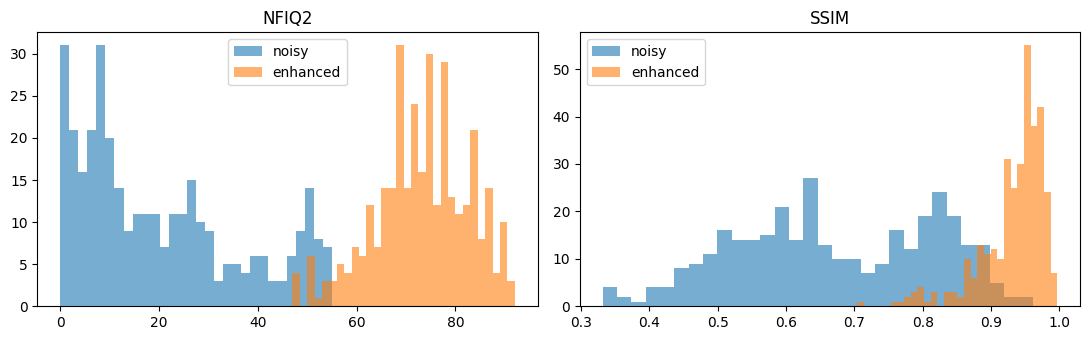

In [13]:
def summ(d):
    t = pd.DataFrame({
        "Before (noisy)":  [d.noisy_ssim.mean(), d.noisy_psnr.mean(), d.noisy_rmse.mean(), d.noisy_nfiq2.mean()],
        "After (enhanced)": [d.enh_ssim.mean(),  d.enh_psnr.mean(),  d.enh_rmse.mean(),  d.enh_nfiq2.mean()]},
        index=["SSIM", "PSNR (dB)", "RMSE", "NFIQ2"])
    t["Change"] = t["After (enhanced)"] - t["Before (noisy)"]
    return t.round(3)

print(f"Test images: {len(res)}"); display(summ(res))
print("Clean reference NFIQ2 mean:", round(res.clean_nfiq2.mean(), 2))
v = res.dropna(subset=["noisy_nfiq2", "enh_nfiq2"])
print(f"NFIQ2 improved on {(v.enh_nfiq2 > v.noisy_nfiq2).sum()} of {len(v)} images")
print(f"SSIM improved on {(res.enh_ssim > res.noisy_ssim).sum()} of {len(res)} images")
for d in "UVSR":
    print(f"\nDevice {d} (n={(res.device == d).sum()})"); display(summ(res[res.device == d]))

fig, ax = plt.subplots(1, 2, figsize=(11, 3.5))
ax[0].hist(res.noisy_nfiq2.dropna(), 30, alpha=.6, label="noisy")
ax[0].hist(res.enh_nfiq2.dropna(), 30, alpha=.6, label="enhanced"); ax[0].set_title("NFIQ2"); ax[0].legend()
ax[1].hist(res.noisy_ssim, 30, alpha=.6, label="noisy")
ax[1].hist(res.enh_ssim, 30, alpha=.6, label="enhanced"); ax[1].set_title("SSIM"); ax[1].legend()
plt.tight_layout(); plt.savefig(OUT/"visuals/hist_nfiq2_ssim.png", dpi=150); plt.show()

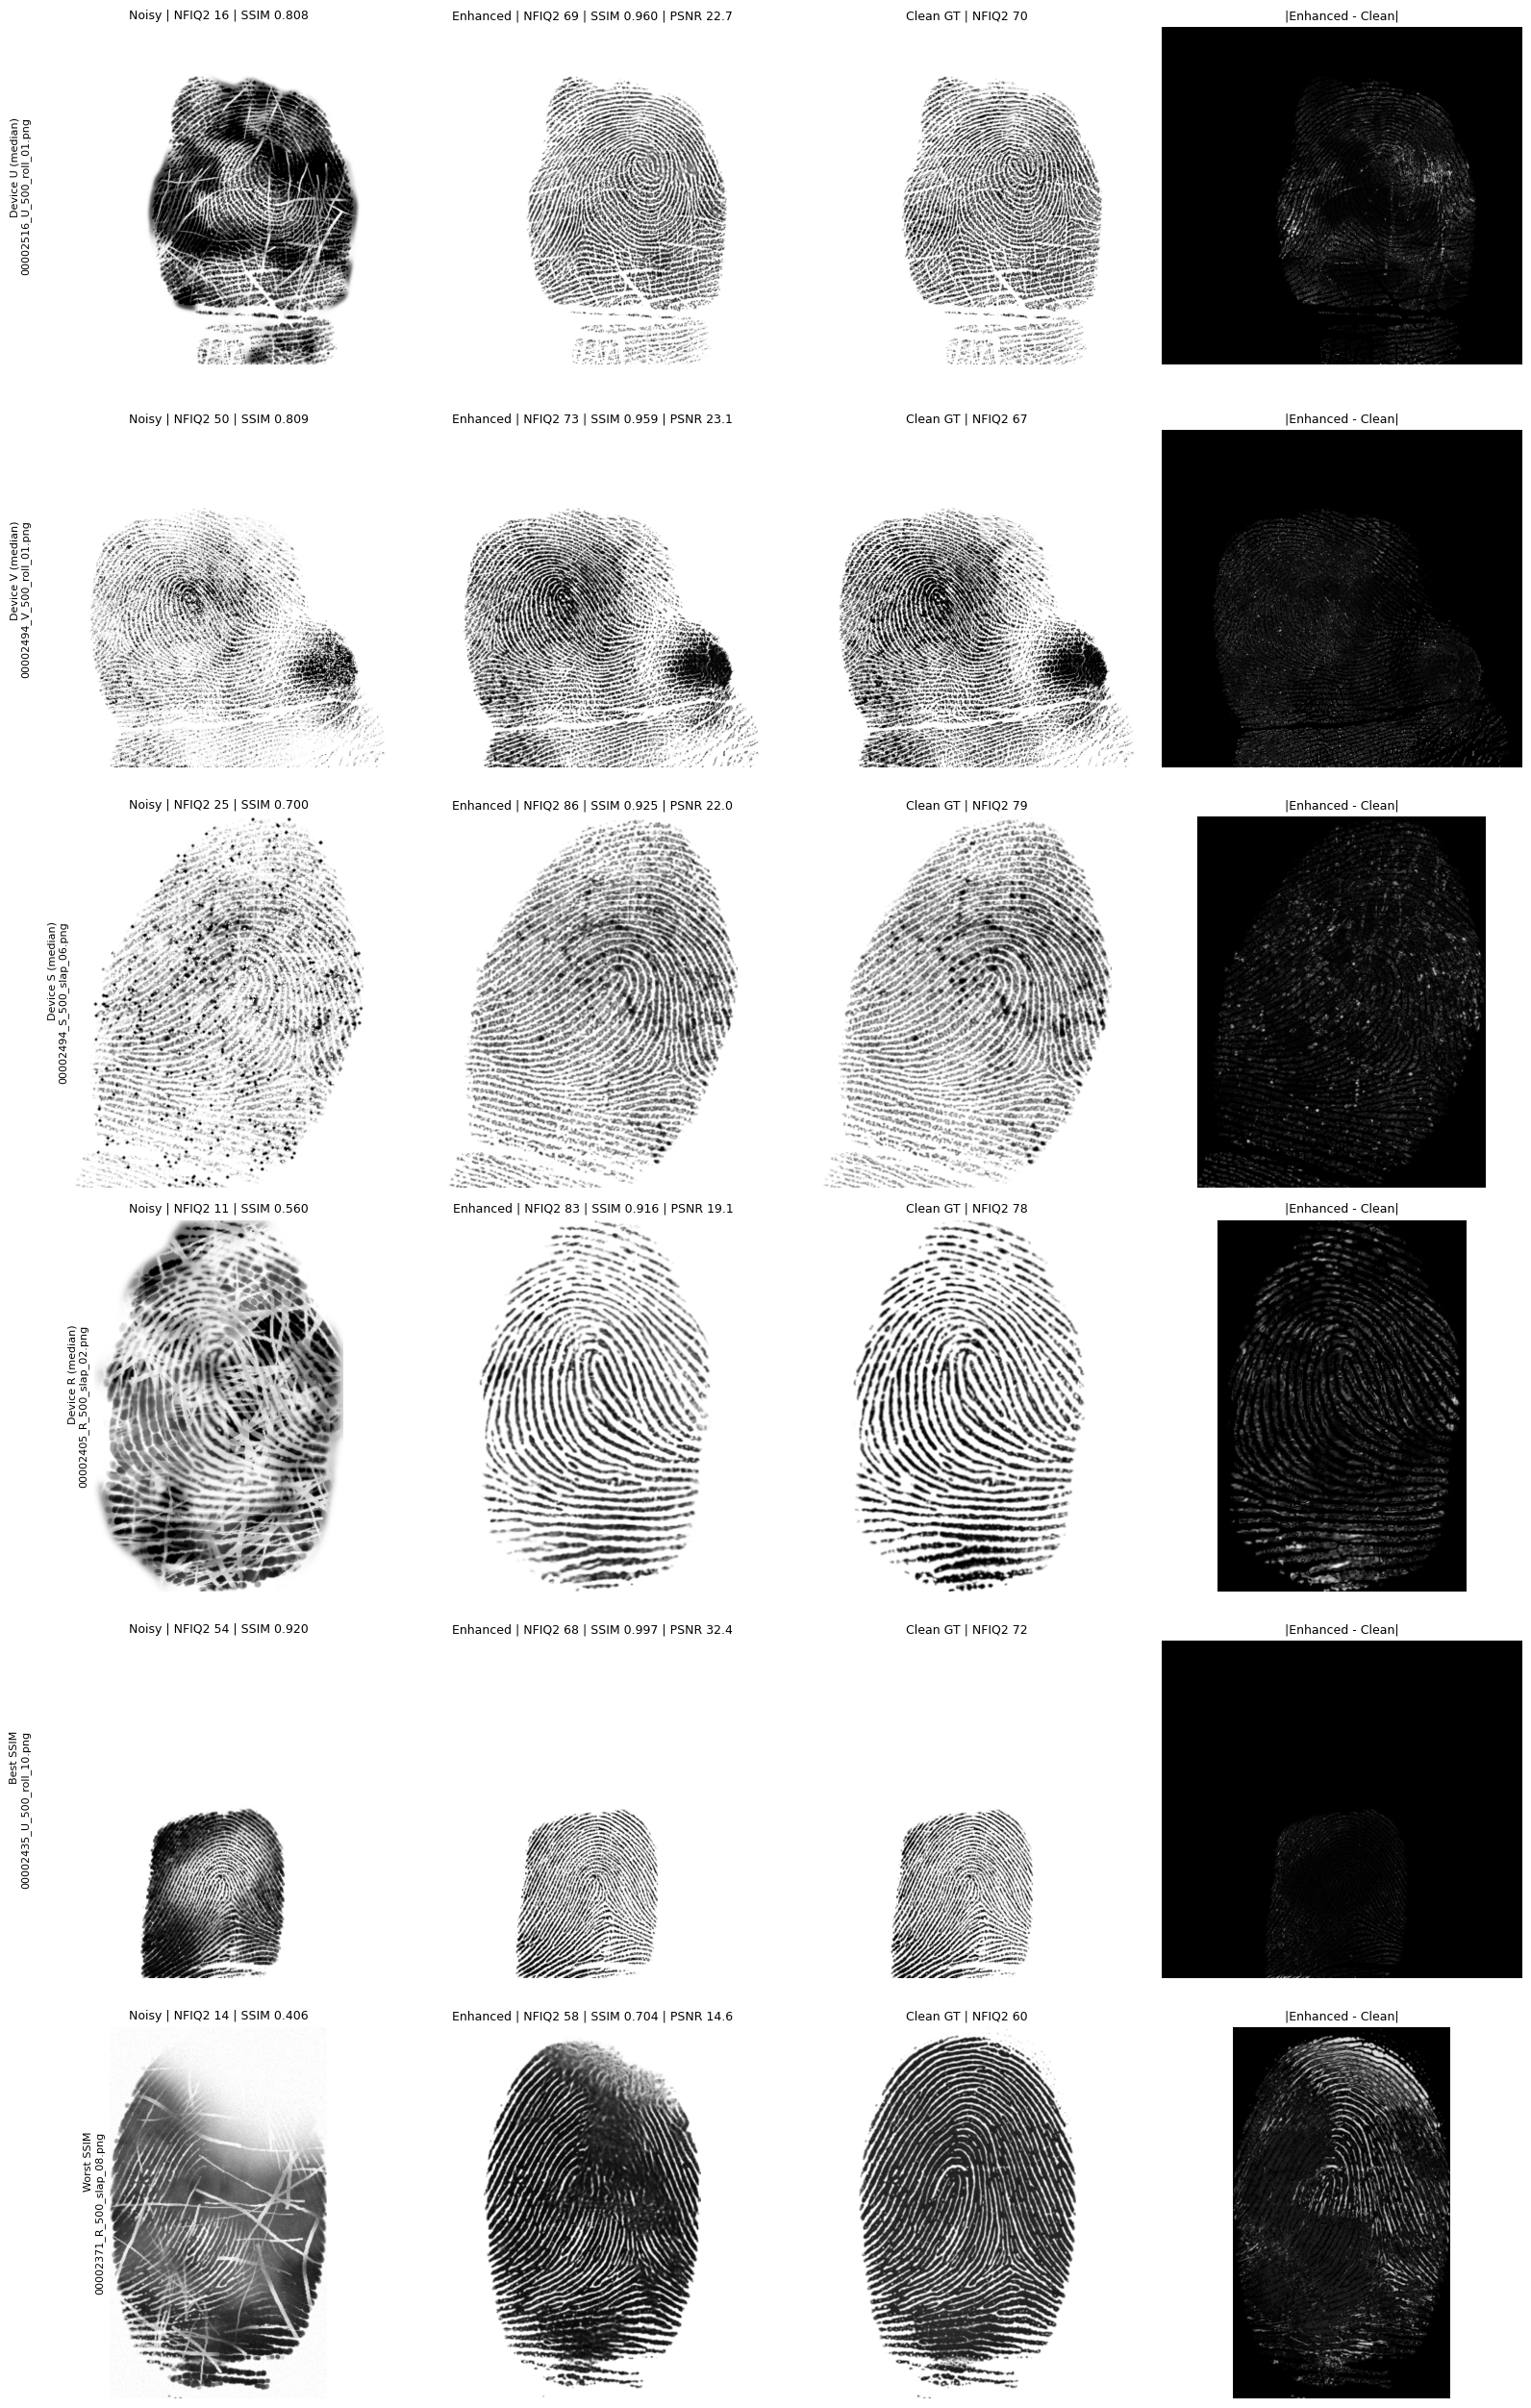

In [14]:
sel = []
for d in "UVSR":
    s = res[res.device == d].sort_values("enh_ssim")
    if len(s): sel.append((f"Device {d} (median)", s.iloc[len(s)//2]))
s = res.sort_values("enh_ssim")
sel += [("Best SSIM", s.iloc[-1]), ("Worst SSIM", s.iloc[0])]

fig, axs = plt.subplots(len(sel), 4, figsize=(16, 4.2*len(sel)))
for i, (tag, r) in enumerate(sel):
    n = cv2.imread(r.noisy, 0); c = cv2.imread(r.clean, 0)
    e = cv2.imread(str(OUT/"enhanced_test"/r.device/r.fname), 0)
    diff = np.abs(e.astype(int) - c.astype(int)).astype(np.uint8)
    items = [(n, f"Noisy | NFIQ2 {r.noisy_nfiq2:.0f} | SSIM {r.noisy_ssim:.3f}"),
             (e, f"Enhanced | NFIQ2 {r.enh_nfiq2:.0f} | SSIM {r.enh_ssim:.3f} | PSNR {r.enh_psnr:.1f}"),
             (c, f"Clean GT | NFIQ2 {r.clean_nfiq2:.0f}"),
             (diff, "|Enhanced - Clean|")]
    for j, (im, t) in enumerate(items):
        axs[i, j].imshow(im, cmap="gray", vmin=0, vmax=255); axs[i, j].set_title(t, fontsize=9)
        axs[i, j].axis("off")
    axs[i, 0].text(-0.02, 0.5, f"{tag}\n{r.fname}", transform=axs[i, 0].transAxes,
                   rotation=90, va="center", ha="right", fontsize=8)
plt.tight_layout(); plt.savefig(OUT/"visuals/before_after.png", dpi=130); plt.show()